#Persiapan dan Load Dataset

In [1]:
!pip -q install mlxtend


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [8]:
import pandas as pd

data = pd.read_csv("BreadBasket.csv")

data.head()

,Date,Time,Transaction,Item
0,2016-10-30,09:58:11,1,Bread
1,2016-10-30,10:05:34,2,Scandinavian
2,2016-10-30,10:05:34,2,Scandinavian
3,2016-10-30,10:07:57,3,Hot chocolate
4,2016-10-30,10:07:57,3,Jam


#Data Understanding dan Cleaning

In [9]:

print("Shape:", data.shape)
print()

print("Kolom:", data.columns.tolist())
print()

print("Tipe data:")
print(data.dtypes)
print()

print("Missing value:")
print(data.isnull().sum())
print()

print("Jumlah transaksi:", data["Transaction"].nunique())
print("Jumlah item unik termasuk NONE:", data["Item"].nunique())
print()

print("Periode data:", data["Date"].min(), "s.d.", data["Date"].max())


Shape: (21293, 4)

Kolom: ['Date', 'Time', 'Transaction', 'Item']

Tipe data:
Date           object
Time           object
Transaction     int64
Item           object
dtype: object

Missing value:
Date           0
Time           0
Transaction    0
Item           0
dtype: int64

Jumlah transaksi: 9531
Jumlah item unik termasuk NONE: 95

Periode data: 2016-10-30 s.d. 2017-04-09


Item
Coffee           5471
Bread            3325
Tea              1435
Cake             1025
Pastry            856
NONE              786
Sandwich          771
Medialuna         616
Hot chocolate     590
Cookies           540
Name: count, dtype: int64


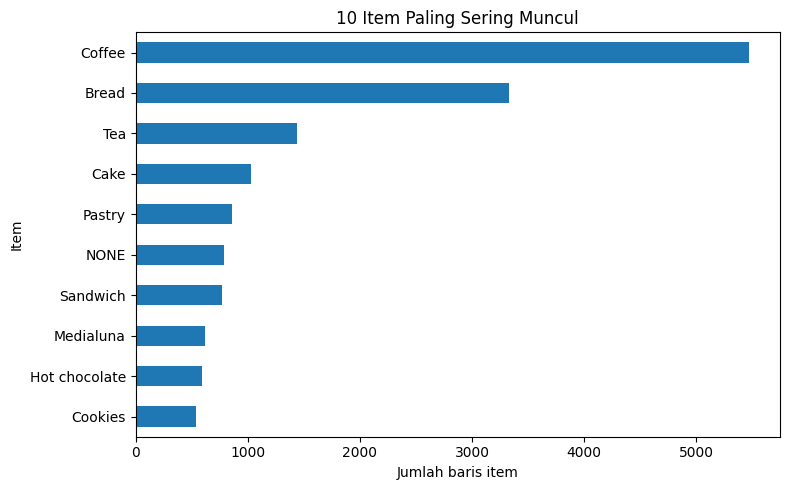

In [10]:

top_items_raw = data["Item"].value_counts().head(10)
print(top_items_raw)

top_items_raw.sort_values().plot(kind="barh", figsize=(8,5))
plt.title("10 Item Paling Sering Muncul")
plt.xlabel("Jumlah baris item")
plt.ylabel("Item")
plt.tight_layout()
plt.show()


In [11]:

none_count = (data["Item"].astype(str).str.upper() == "NONE").sum()
print("Jumlah baris NONE:", none_count)

data_clean = data[data["Item"].astype(str).str.upper() != "NONE"].copy()

print("Jumlah baris setelah cleaning:", len(data_clean))
print("Jumlah item valid:", data_clean["Item"].nunique())
print("Jumlah transaksi valid:", data_clean["Transaction"].nunique())


Jumlah baris NONE: 786
Jumlah baris setelah cleaning: 20507
Jumlah item valid: 94
Jumlah transaksi valid: 9465


#Membentuk Basket Transaksi

In [12]:

transactions = (
    data_clean.groupby("Transaction")["Item"]
    .apply(lambda x: sorted(set(x)))
    .tolist()
)

print("Jumlah basket transaksi:", len(transactions))
print()

print("Contoh 5 transaksi pertama:")
for i, basket in enumerate(transactions[:5], start=1):
    print(f"T{i}: {basket}")


Jumlah basket transaksi: 9465

Contoh 5 transaksi pertama:
T1: ['Bread']
T2: ['Scandinavian']
T3: ['Cookies', 'Hot chocolate', 'Jam']
T4: ['Muffin']
T5: ['Bread', 'Coffee', 'Pastry']


In [13]:

transaction_item_counts = (
    data_clean[["Transaction", "Item"]]
    .drop_duplicates()
    ["Item"]
    .value_counts()
    .head(10)
)

transaction_item_counts


Item
Coffee           4528
Bread            3097
Tea              1350
Cake              983
Pastry            815
Sandwich          680
Medialuna         585
Hot chocolate     552
Cookies           515
Brownie           379
Name: count, dtype: int64

# Transaction Encoding 

In [14]:

te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

transaction_df = pd.DataFrame(te_array, columns=te.columns_)

print("Shape encoded transaction:", transaction_df.shape)
transaction_df.head()


Shape encoded transaction: (9465, 94)


,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#Frequent Itemset dengan Apriori 

In [15]:

MIN_SUPPORT = 0.03

frequent_itemsets = apriori(
    transaction_df,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

print("Jumlah frequent itemset:", len(frequent_itemsets))
frequent_itemsets.head(20)


Jumlah frequent itemset: 23


,support,itemsets,length
0,0.478394,(Coffee),1
1,0.327205,(Bread),1
2,0.142631,(Tea),1
3,0.103856,(Cake),1
4,0.090016,"(Coffee, Bread)",2
5,0.086107,(Pastry),1
6,0.071844,(Sandwich),1
7,0.061807,(Medialuna),1
8,0.058320,(Hot chocolate),1
9,0.054728,"(Coffee, Cake)",2


In [16]:
frequent_itemsets[frequent_itemsets["length"] >= 2].sort_values(
    "support",
    ascending=False
)

,support,itemsets,length
4,0.090016,"(Coffee, Bread)",2
9,0.054728,"(Coffee, Cake)",2
11,0.049868,"(Tea, Coffee)",2
12,0.047544,"(Pastry, Coffee)",2
17,0.038246,"(Coffee, Sandwich)",2
19,0.035182,"(Coffee, Medialuna)",2


# Membentuk Association Rules 

In [17]:

# Membentuk seluruh rule yang memungkinkan dari frequent itemset
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.0
)

rules = rules.sort_values(
    ["lift", "confidence"],
    ascending=False
).reset_index(drop=True)

print("Jumlah seluruh rule:", len(rules))

rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(20)


Jumlah seluruh rule: 12


,antecedents,consequents,support,confidence,lift
0,(Medialuna),(Coffee),0.035182,0.569231,1.189878
1,(Coffee),(Medialuna),0.035182,0.073542,1.189878
2,(Pastry),(Coffee),0.047544,0.552147,1.154168
3,(Coffee),(Pastry),0.047544,0.099382,1.154168
4,(Sandwich),(Coffee),0.038246,0.532353,1.112792
5,(Coffee),(Sandwich),0.038246,0.079947,1.112792
6,(Cake),(Coffee),0.054728,0.526958,1.101515
7,(Coffee),(Cake),0.054728,0.114399,1.101515
8,(Coffee),(Tea),0.049868,0.104240,0.730840
9,(Tea),(Coffee),0.049868,0.349630,0.730840


In [18]:

strong_rules = rules[
    (rules["confidence"] >= 0.50) &
    (rules["lift"] > 1)
].copy()

strong_rules = strong_rules.sort_values(
    ["lift", "confidence"],
    ascending=False
)

strong_rules[["antecedents", "consequents", "support", "confidence", "lift"]]


,antecedents,consequents,support,confidence,lift
0,(Medialuna),(Coffee),0.035182,0.569231,1.189878
2,(Pastry),(Coffee),0.047544,0.552147,1.154168
4,(Sandwich),(Coffee),0.038246,0.532353,1.112792
6,(Cake),(Coffee),0.054728,0.526958,1.101515


# Interpretasi Rule

In [19]:

rules_display = rules.copy()

rules_display["antecedents_str"] = rules_display["antecedents"].apply(
    lambda x: ", ".join(sorted(x))
)

rules_display["consequents_str"] = rules_display["consequents"].apply(
    lambda x: ", ".join(sorted(x))
)

rules_display[
    ["antecedents_str", "consequents_str", "support", "confidence", "lift"]
].head(20)


,antecedents_str,consequents_str,support,confidence,lift
0,Medialuna,Coffee,0.035182,0.569231,1.189878
1,Coffee,Medialuna,0.035182,0.073542,1.189878
2,Pastry,Coffee,0.047544,0.552147,1.154168
3,Coffee,Pastry,0.047544,0.099382,1.154168
4,Sandwich,Coffee,0.038246,0.532353,1.112792
5,Coffee,Sandwich,0.038246,0.079947,1.112792
6,Cake,Coffee,0.054728,0.526958,1.101515
7,Coffee,Cake,0.054728,0.114399,1.101515
8,Coffee,Tea,0.049868,0.104240,0.730840
9,Tea,Coffee,0.049868,0.349630,0.730840


In [20]:
cake_to_coffee = rules_display[
    (rules_display["antecedents_str"] == "Cake") &
    (rules_display["consequents_str"] == "Coffee")
][["antecedents_str", "consequents_str", "support", "confidence", "lift"]]

cake_to_coffee

,antecedents_str,consequents_str,support,confidence,lift
6,Cake,Coffee,0.054728,0.526958,1.101515


In [21]:
def compare_direction(item_a, item_b, rule_table):
    cols = ["antecedents_str", "consequents_str", "support", "confidence", "lift"]

    result = rule_table[
        ((rule_table["antecedents_str"] == item_a) & (rule_table["consequents_str"] == item_b)) |
        ((rule_table["antecedents_str"] == item_b) & (rule_table["consequents_str"] == item_a))
    ]

    return result[cols]


compare_direction("Cake", "Coffee", rules_display)

,antecedents_str,consequents_str,support,confidence,lift
6,Cake,Coffee,0.054728,0.526958,1.101515
7,Coffee,Cake,0.054728,0.114399,1.101515


#Visualisasi Association Rules 

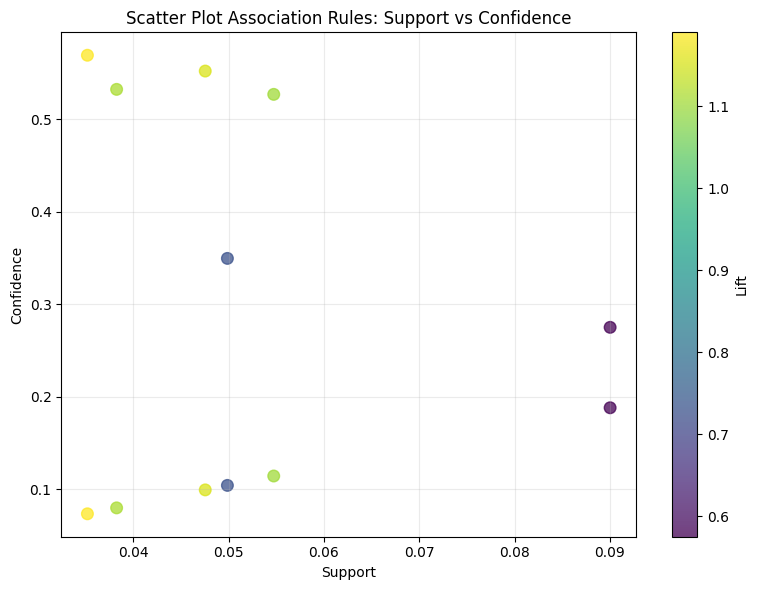

In [22]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    alpha=0.75,
    s=70
)

plt.colorbar(scatter, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Scatter Plot Association Rules: Support vs Confidence")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

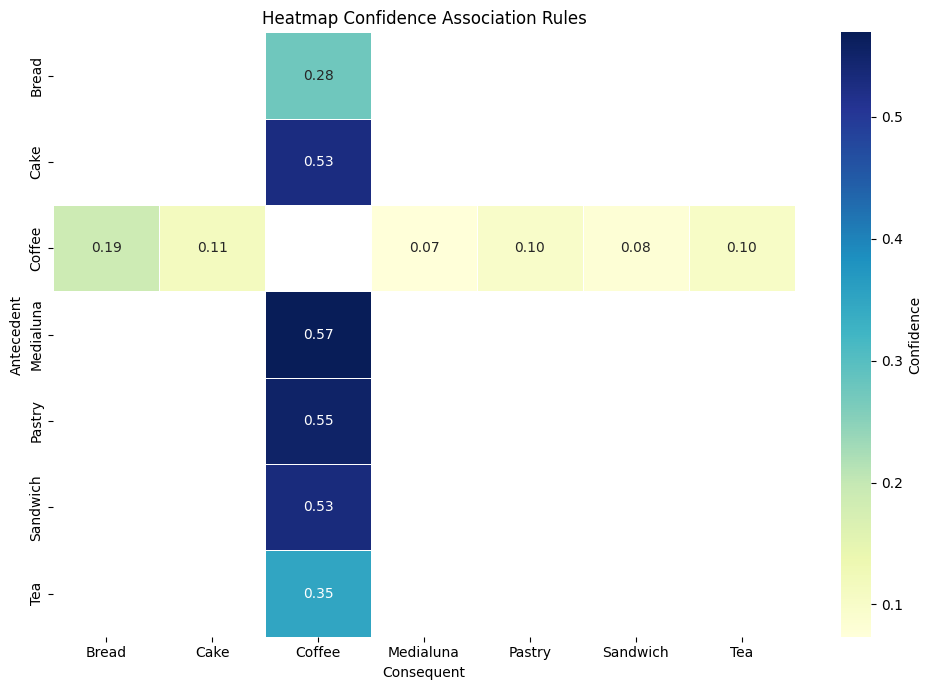

In [23]:
rules_single = rules[
    (rules["antecedents"].apply(len) == 1) &
    (rules["consequents"].apply(len) == 1)
].copy()

rules_single["antecedent"] = rules_single["antecedents"].apply(
    lambda x: next(iter(x))
)

rules_single["consequent"] = rules_single["consequents"].apply(
    lambda x: next(iter(x))
)

confidence_matrix = rules_single.pivot_table(
    index="antecedent",
    columns="consequent",
    values="confidence",
    aggfunc="max"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    confidence_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Confidence"}
)

plt.title("Heatmap Confidence Association Rules")
plt.xlabel("Consequent")
plt.ylabel("Antecedent")
plt.tight_layout()
plt.show()

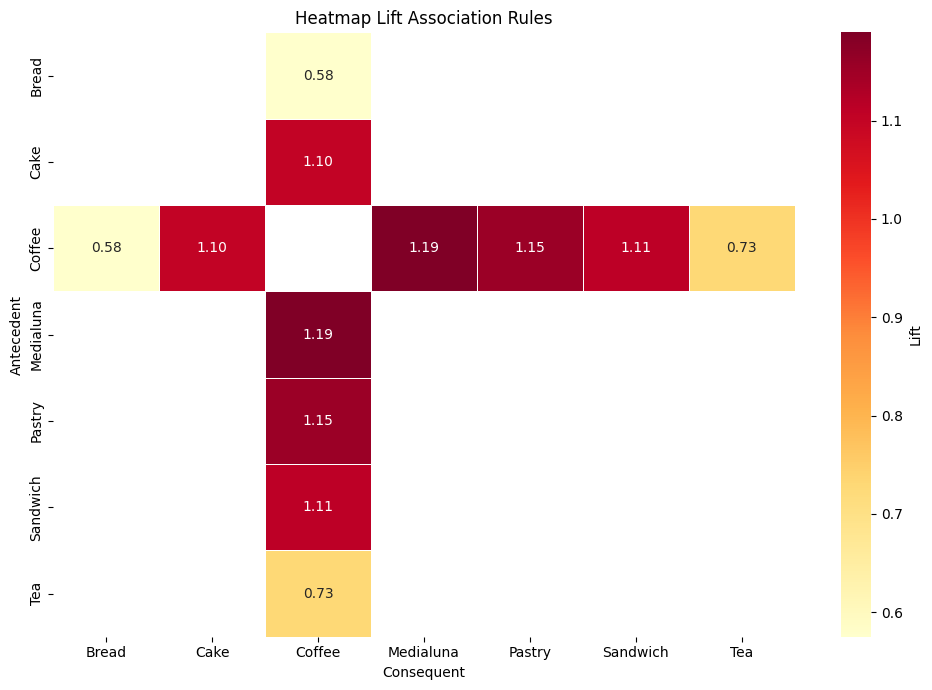

In [24]:
lift_matrix = rules_single.pivot_table(
    index="antecedent",
    columns="consequent",
    values="lift",
    aggfunc="max"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    lift_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Lift"}
)

plt.title("Heatmap Lift Association Rules")
plt.xlabel("Consequent")
plt.ylabel("Antecedent")
plt.tight_layout()
plt.show()

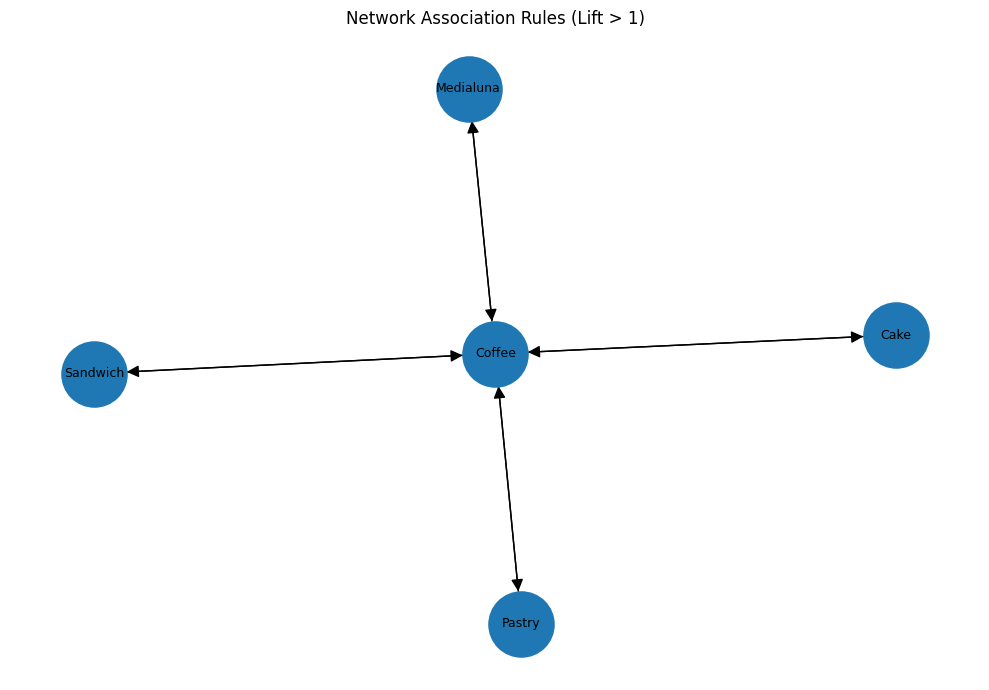

In [25]:
network_rules = rules_single[rules_single["lift"] > 1].copy()
network_rules = network_rules.sort_values("lift", ascending=False).head(15)

G = nx.DiGraph()

for _, row in network_rules.iterrows():
    G.add_edge(
        row["antecedent"],
        row["consequent"],
        weight=row["lift"]
    )

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=2200,
    font_size=9,
    arrows=True,
    arrowsize=18
)

plt.title("Network Association Rules (Lift > 1)")
plt.axis("off")
plt.tight_layout()
plt.show()

#Skenario Threshold Min-Support

In [26]:
for min_sup in [0.02, 0.03, 0.05]:
    fi = apriori(transaction_df, min_support=min_sup, use_colnames=True)

    if len(fi) == 0:
        print(f"min_support={min_sup}: tidak ada frequent itemset")
        continue

    r = association_rules(fi, metric="confidence", min_threshold=0.0)
    strong = r[(r["confidence"] >= 0.50) & (r["lift"] > 1)]

    print(
        f"min_support={min_sup:.2f} | "
        f"frequent itemset={len(fi)} | "
        f"seluruh rule={len(r)} | "
        f"rule terpilih={len(strong)}"
    )

min_support=0.02 | frequent itemset=33 | seluruh rule=28 | rule terpilih=8
min_support=0.03 | frequent itemset=23 | seluruh rule=12 | rule terpilih=4
min_support=0.05 | frequent itemset=11 | seluruh rule=4 | rule terpilih=1
